# IGNITE H&E — Mean Teacher Semi-Supervised Segmentation (Google Colab)

This notebook trains a **Mean Teacher** model for the IGNITE v2 **H&E tissue-compartment segmentation** task using a free Google Colab GPU.

## What it does
1. Mounts Google Drive and copies only `images/he` and `annotations/he` to Colab's temporary disk for faster reads.
2. Rebuilds the same patient-grouped train/validation split used by the supervised baseline (seed 42, validation fraction 20%).
3. Splits the training patients into a labelled subset and an unlabelled subset (default: 20% labelled patients, 80% unlabelled patients).
4. Trains a student U-Net and an EMA teacher U-Net.
5. Uses supervised cross-entropy on labelled masks and confidence-filtered consistency loss on unlabelled images.
6. Validates the **teacher** on the fixed validation set and saves checkpoints/results to Google Drive.

## Important research choices
- **Do not initialize this experiment from the existing fully supervised `best_model.pth` if that model saw all training masks.** That would leak information from the images you are now treating as unlabelled. Both student and teacher start from the same ImageNet-pretrained ResNet34 encoder instead.
- Labelled/unlabelled separation is done by **patient**, not by random ROI, to avoid putting different ROIs from the same patient into both groups.
- The unlabelled dataset class reads **only image files**. It does not read or use their annotation masks.
- The validation split is fixed and its masks are used only for evaluation. The official test split is not used here.
- For a fair research comparison, you should later train a **supervised control using the exact same labelled 20% patient subset**. The earlier full-supervision baseline is a useful reference, but not a label-budget-matched comparison.

> Start with the defaults for a pipeline run. Free Colab GPU availability and session length vary. Checkpointing is performed every epoch.

## 1. Enable GPU and mount Google Drive

In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU), then run this cell.

In [1]:
from google.colab import drive
from pathlib import Path
import os, shutil, random, math, time, gc, json, copy
from functools import lru_cache

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

drive.mount('/content/drive')

import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. In Colab choose Runtime → Change runtime type → GPU, then rerun.")
print("GPU:", torch.cuda.get_device_name(0))
print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.1f} GB")

Mounted at /content/drive
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.6 GB


## 2. Configuration

The defaults are conservative for a free GPU. Change the labelled fraction only when you deliberately define a new experiment.

In [2]:
# Drive folder: expected to contain extracted folders, not ZIP files.
DRIVE_DATA_DIR = Path("/content/drive/MyDrive/IGNITE")
DRIVE_IMAGES_HE = DRIVE_DATA_DIR / "images" / "he"
DRIVE_MASKS_HE = DRIVE_DATA_DIR / "annotations" / "he"
DRIVE_CSV = DRIVE_DATA_DIR / "data_overview.csv"
DRIVE_LABEL_MAP = DRIVE_DATA_DIR / "he_label_map.json"

# Stage H&E only to Colab's temporary disk (faster than reading thousands of files from Drive).
DATA_ROOT = Path("/content/ignite_mean_teacher_data")
LOCAL_IMAGES_HE = DATA_ROOT / "images" / "he"
LOCAL_MASKS_HE = DATA_ROOT / "annotations" / "he"
CSV_PATH = DATA_ROOT / "data_overview.csv"
LABEL_MAP_PATH = DATA_ROOT / "he_label_map.json"

OUTPUT_DIR = DRIVE_DATA_DIR / "training_outputs" / "ignite_he_mean_teacher_20pct"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Data and split configuration — keep the validation settings identical to the baseline.
SEED = 42
VAL_FRACTION = 0.20
LABELED_FRACTION = 0.20       # fraction of TRAINING PATIENTS used with masks
LABEL_SPLIT_SEED = 123        # reproducibly selects labelled training patients

# Training configuration
PATCH_SIZE = 512
BATCH_SIZE = 2                 # lower to 1 if you get CUDA out-of-memory
PATCHES_PER_ROI_PER_EPOCH = 1
EPOCHS = 10                    # begin with 10; increase after the run is stable
MAX_STEPS_PER_EPOCH = 100      # set None to use every unlabelled batch in each epoch
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0                # robust for Colab and cached image loading

# Mean Teacher configuration
EMA_DECAY = 0.99
CONFIDENCE_THRESHOLD = 0.70    # teacher pixels below this confidence are ignored
MAX_CONSISTENCY_WEIGHT = 0.5
CONSISTENCY_RAMPUP_EPOCHS = 5

NUM_CLASSES = 17               # IDs 0..16
IGNORE_INDEX = 0               # 0 = Unannotated; 1 = actual Background
USE_IMAGENET_NORMALIZATION = True
RESUME_TRAINING = False        # set True after reconnecting to resume last_checkpoint.pth

print("Data folder:", DRIVE_DATA_DIR)
print("Mean Teacher outputs:", OUTPUT_DIR)
print(f"Label budget: {LABELED_FRACTION:.0%} of training patients")

Data folder: /content/drive/MyDrive/IGNITE
Mean Teacher outputs: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_mean_teacher_20pct
Label budget: 20% of training patients


## 3. Check folders and stage H&E data locally

The notebook expects your already-extracted Google Drive folders: `IGNITE/images/he`, `IGNITE/annotations/he`, `data_overview.csv`, and `he_label_map.json`. It does not require ZIP files.

In [3]:
required_paths = [DRIVE_IMAGES_HE, DRIVE_MASKS_HE, DRIVE_CSV, DRIVE_LABEL_MAP]
missing = [str(p) for p in required_paths if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Missing required items in Google Drive. Check the folder structure:\n" + "\n".join(missing)
    )

DATA_ROOT.mkdir(parents=True, exist_ok=True)

# Copy once per Colab runtime. If you change files in Drive, delete the marker and rerun.
copy_marker = DATA_ROOT / ".he_data_staged"
if not copy_marker.exists():
    print("Copying H&E images from Drive to Colab local storage...")
    shutil.copytree(DRIVE_IMAGES_HE, LOCAL_IMAGES_HE, dirs_exist_ok=True)
    print("Copying H&E annotations from Drive to Colab local storage...")
    shutil.copytree(DRIVE_MASKS_HE, LOCAL_MASKS_HE, dirs_exist_ok=True)
    shutil.copy2(DRIVE_CSV, CSV_PATH)
    shutil.copy2(DRIVE_LABEL_MAP, LABEL_MAP_PATH)
    copy_marker.write_text("done")
else:
    print("H&E data already staged in this runtime; skipping copy.")

image_files = list(LOCAL_IMAGES_HE.rglob("*.png"))
mask_files = list(LOCAL_MASKS_HE.rglob("*.png"))
print(f"Local H&E images: {len(image_files)}")
print(f"Local H&E masks:  {len(mask_files)}")
print(f"CSV exists: {CSV_PATH.is_file()} | label map exists: {LABEL_MAP_PATH.is_file()}")
if not image_files or not mask_files:
    raise FileNotFoundError("No PNG images or masks found. Check images/he and annotations/he.")

Copying H&E images from Drive to Colab local storage...
Copying H&E annotations from Drive to Colab local storage...
Local H&E images: 816
Local H&E masks:  816
CSV exists: True | label map exists: True


## 4. Read metadata and pair images with masks

The notebook prefers a matching `_with_context.png` image and mask pair, then falls back to the plain ROI pair. Filenames are kept unchanged.

In [4]:
df_all = pd.read_csv(CSV_PATH)
required_columns = {"patient_id", "name", "task", "image_path", "annotation_path", "split", "validation_fold"}
missing_columns = required_columns - set(df_all.columns)
if missing_columns:
    raise ValueError(f"data_overview.csv is missing columns: {sorted(missing_columns)}")

he_df = df_all[df_all["task"].astype(str) == "he_tissue_segmentation"].copy().reset_index(drop=True)
if he_df.empty:
    raise ValueError("No rows found for task='he_tissue_segmentation'.")

image_index = {p.name: p for p in LOCAL_IMAGES_HE.rglob("*.png")}
mask_index = {p.name: p for p in LOCAL_MASKS_HE.rglob("*.png")}

def candidate_names(csv_path_value):
    base = Path(str(csv_path_value)).name
    stem = Path(base).stem
    if stem.endswith("_with_context"):
        plain_stem = stem[:-len("_with_context")]
        return [base, plain_stem + ".png"]
    return [stem + "_with_context.png", base]

resolved_rows, missing_pairs = [], []
for row in he_df.to_dict("records"):
    img_candidates = candidate_names(row["image_path"])
    mask_candidates = candidate_names(row["annotation_path"])
    found = None
    for img_name, mask_name in zip(img_candidates, mask_candidates):
        if img_name in image_index and mask_name in mask_index:
            found = (image_index[img_name], mask_index[mask_name], img_name.endswith("_with_context.png"))
            break
    if found is None:
        missing_pairs.append((row["name"], img_candidates, mask_candidates))
        continue
    img_path, mask_path, used_context = found
    row["resolved_image"] = str(img_path)
    row["resolved_mask"] = str(mask_path)
    row["used_context"] = bool(used_context)
    resolved_rows.append(row)

if missing_pairs:
    print("First missing pairs:", missing_pairs[:5])
    raise FileNotFoundError(f"Could not resolve {len(missing_pairs)} H&E image/mask pairs.")

he_df = pd.DataFrame(resolved_rows).reset_index(drop=True)
print(f"Paired H&E ROIs: {len(he_df)}")
print("Context pairs:", int(he_df["used_context"].sum()))
print("Plain pairs:", int((~he_df["used_context"]).sum()))
display(he_df[["patient_id", "name", "split", "validation_fold", "used_context"]].head())

Paired H&E ROIs: 408
Context pairs: 408
Plain pairs: 0


,patient_id,name,split,validation_fold,used_context
0,1,patient1_he_roi1,train,fold3,True
1,1,patient1_he_roi2,train,fold0,True
2,1,patient1_he_roi3,train,fold1,True
3,1,patient1_he_roi4,train,fold2,True
4,1,patient1_he_roi5,train,fold2,True


## 5. Validate label map and image/mask pairs

IGNITE uses stored IDs 0–16. **ID 0 is unannotated and ignored; ID 1 is background.**

In [5]:
with open(LABEL_MAP_PATH, "r", encoding="utf-8") as f:
    label_map = json.load(f)
id_to_label = {int(v): k for k, v in label_map.items()}
if set(id_to_label) != set(range(NUM_CLASSES)):
    raise ValueError(f"Expected label IDs 0..16; found {sorted(id_to_label)}")

for class_id in range(NUM_CLASSES):
    print(f"{class_id:2d}: {id_to_label[class_id]}")

def read_image_mask(image_path, mask_path):
    image = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.uint8)
    mask = np.asarray(Image.open(mask_path))
    if mask.ndim == 3:
        if mask.shape[2] >= 3 and np.array_equal(mask[..., 0], mask[..., 1]) and np.array_equal(mask[..., 0], mask[..., 2]):
            mask = mask[..., 0]
        else:
            raise ValueError(f"Expected single-channel class-ID mask: {mask_path}; got {mask.shape}")
    mask = mask.astype(np.uint8, copy=False)
    if image.shape[:2] != mask.shape:
        raise ValueError(f"Image/mask shape mismatch for {Path(image_path).name}: {image.shape[:2]} vs {mask.shape}")
    ids = np.unique(mask)
    if np.any(ids >= NUM_CLASSES):
        raise ValueError(f"Unexpected mask IDs {ids.tolist()} in {mask_path}")
    return image, mask

for _, r in he_df.sample(min(5, len(he_df)), random_state=SEED).iterrows():
    im, mk = read_image_mask(r["resolved_image"], r["resolved_mask"])
    print(f"{r['name']}: image={im.shape}, mask={mk.shape}, IDs={np.unique(mk).tolist()}")

 0: Unannotated
 1: Background
 2: Tumor epithelium
 3: Reactive epithelium
 4: Stroma
 5: Inflammation
 6: Alveolar tissue
 7: Fatty tissue
 8: Necrotic tissue
 9: Erythrocytes
10: Bronchial epithelium
11: Mucus/Plasma/Fluids
12: Cartilage/Bone
13: Macrophages
14: Muscle
15: Liver
16: Keratinization
patient21_he_roi2: image=(1536, 1792, 3), mask=(1536, 1792), IDs=[0, 1, 4, 9]
patient56_he_roi3: image=(2560, 2560, 3), mask=(2560, 2560), IDs=[0, 1, 2, 4, 8, 9, 13]
patient66_he_roi4: image=(3072, 1792, 3), mask=(3072, 1792), IDs=[0, 1, 3, 4, 5, 6, 9, 11, 13]
patient9_he_roi1: image=(1792, 1792, 3), mask=(1792, 1792), IDs=[0, 1, 2, 4, 8, 9]
patient12_he_roi1: image=(1792, 1792, 3), mask=(1792, 1792), IDs=[0, 1, 2, 4, 6, 8, 9, 13]


## 6. Recreate the fixed validation split, then create labelled/unlabelled training pools

The first split is patient-grouped and uses the baseline defaults (`SEED=42`, `VAL_FRACTION=0.20`). Then only the training patients are divided into labelled and unlabelled groups. Validation and official test masks are never used for training.

In [6]:
from sklearn.model_selection import GroupShuffleSplit

train_pool_df = he_df[he_df["split"].astype(str).str.lower() == "train"].copy().reset_index(drop=True)
test_df = he_df[he_df["split"].astype(str).str.lower() == "test"].copy().reset_index(drop=True)
if train_pool_df.empty:
    raise ValueError("No H&E rows with split='train'.")

# Same patient-grouped split settings as the supervised notebook defaults.
outer_splitter = GroupShuffleSplit(n_splits=1, test_size=VAL_FRACTION, random_state=SEED)
train_idx, val_idx = next(outer_splitter.split(train_pool_df, groups=train_pool_df["patient_id"].astype(str)))
train_df = train_pool_df.iloc[train_idx].copy().reset_index(drop=True)
val_df = train_pool_df.iloc[val_idx].copy().reset_index(drop=True)

# Select labelled patients; all other training patients are image-only/unlabelled.
if train_df["patient_id"].nunique() < 2:
    raise ValueError("Not enough training patients for a patient-level labelled/unlabelled split.")
label_splitter = GroupShuffleSplit(
    n_splits=1, test_size=1.0 - LABELED_FRACTION, random_state=LABEL_SPLIT_SEED
)
labeled_idx, unlabeled_idx = next(
    label_splitter.split(train_df, groups=train_df["patient_id"].astype(str))
)
labeled_df = train_df.iloc[labeled_idx].copy().reset_index(drop=True)
unlabeled_df = train_df.iloc[unlabeled_idx].copy().reset_index(drop=True)

train_patients = set(train_df["patient_id"].astype(str))
val_patients = set(val_df["patient_id"].astype(str))
labeled_patients = set(labeled_df["patient_id"].astype(str))
unlabeled_patients = set(unlabeled_df["patient_id"].astype(str))
assert not (train_patients & val_patients), "Patient leakage between training and validation!"
assert not (labeled_patients & unlabeled_patients), "Patient overlap between labelled and unlabelled pools!"

print(f"Training pool: {len(train_df)} ROIs | {len(train_patients)} patients")
print(f"Labelled:      {len(labeled_df)} ROIs | {len(labeled_patients)} patients")
print(f"Unlabelled:    {len(unlabeled_df)} ROIs | {len(unlabeled_patients)} patients")
print(f"Validation:    {len(val_df)} ROIs | {len(val_patients)} patients")
print(f"Official test: {len(test_df)} ROIs (untouched)")
print(f"Actual labelled patient fraction: {len(labeled_patients) / max(1, len(train_patients)):.1%}")

# Store split IDs for reproducibility and checkpoint validation.
labeled_patient_ids = sorted(labeled_patients)
unlabeled_patient_ids = sorted(unlabeled_patients)
validation_patient_ids = sorted(val_patients)
labeled_records = labeled_df.to_dict("records")
unlabeled_records = unlabeled_df.to_dict("records")
val_records = val_df.to_dict("records")

Training pool: 218 ROIs | 38 patients
Labelled:      32 ROIs | 7 patients
Unlabelled:    186 ROIs | 31 patients
Validation:    51 ROIs | 10 patients
Official test: 139 ROIs (untouched)
Actual labelled patient fraction: 18.4%


## 7. Install model package and set seeds

In [7]:
%pip -q install -U segmentation-models-pytorch

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")
print("Segmentation Models PyTorch:", getattr(smp, "__version__", "installed"))
print("Device:", device)

Segmentation Models PyTorch: 0.6.0
Device: cuda


## 8. Patch datasets and aligned augmentations

For each unlabelled image patch, the teacher receives a **weak** view and the student receives a **stronger colour/intensity** view. Both views receive exactly the same crop, flips, and rotations, so corresponding pixels remain aligned for consistency loss.

The unlabelled dataset deliberately opens only the image file; it never opens its annotation mask.

In [8]:
from functools import lru_cache

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

@lru_cache(maxsize=8)
def cached_image(image_path: str):
    return np.asarray(Image.open(image_path).convert("RGB"), dtype=np.uint8)

@lru_cache(maxsize=6)
def cached_pair(image_path: str, mask_path: str):
    image, mask = read_image_mask(image_path, mask_path)
    coords = np.argwhere(mask > IGNORE_INDEX)
    if len(coords) > 50000:
        rng = np.random.default_rng(abs(hash((image_path, mask_path))) % (2**32))
        coords = coords[rng.choice(len(coords), size=50000, replace=False)]
    return image, mask, coords

def pad_image(image, patch_size):
    h, w = image.shape[:2]
    pad_h, pad_w = max(0, patch_size-h), max(0, patch_size-w)
    if pad_h or pad_w:
        mode = "reflect" if h > 1 and w > 1 else "edge"
        image = np.pad(image, ((0,pad_h),(0,pad_w),(0,0)), mode=mode)
    return image

def pad_image_mask(image, mask, patch_size):
    h, w = mask.shape
    pad_h, pad_w = max(0, patch_size-h), max(0, patch_size-w)
    if pad_h or pad_w:
        mode = "reflect" if h > 1 and w > 1 else "edge"
        image = np.pad(image, ((0,pad_h),(0,pad_w),(0,0)), mode=mode)
        mask = np.pad(mask, ((0,pad_h),(0,pad_w)), mode="constant", constant_values=IGNORE_INDEX)
    return image, mask

def choose_crop(image, patch_size, coords=None):
    h, w = image.shape[:2]
    if coords is not None and len(coords):
        cy, cx = coords[random.randrange(len(coords))]
        top = min(max(int(cy) - patch_size//2, 0), h-patch_size)
        left = min(max(int(cx) - patch_size//2, 0), w-patch_size)
    else:
        top = random.randint(0, max(0, h-patch_size))
        left = random.randint(0, max(0, w-patch_size))
    return top, left

def geometric_augment(image, mask=None):
    if random.random() < 0.5:
        image = np.fliplr(image)
        if mask is not None: mask = np.fliplr(mask)
    if random.random() < 0.5:
        image = np.flipud(image)
        if mask is not None: mask = np.flipud(mask)
    k = random.randrange(4)
    if k:
        image = np.rot90(image, k)
        if mask is not None: mask = np.rot90(mask, k)
    if mask is None:
        return np.ascontiguousarray(image)
    return np.ascontiguousarray(image), np.ascontiguousarray(mask)

def strong_colour_augment(image):
    x = image.astype(np.float32)
    if random.random() < 0.8:
        brightness = random.uniform(0.85, 1.15)
        x *= brightness
    if random.random() < 0.8:
        contrast = random.uniform(0.85, 1.15)
        mean = x.mean(axis=(0,1), keepdims=True)
        x = (x - mean) * contrast + mean
    if random.random() < 0.5:
        gray = x.mean(axis=2, keepdims=True)
        saturation = random.uniform(0.85, 1.15)
        x = (x - gray) * saturation + gray
    if random.random() < 0.2:
        x += np.random.normal(0, 2.0, size=x.shape).astype(np.float32)
    return np.clip(x, 0, 255).astype(np.uint8)

def image_to_tensor(image):
    x = image.astype(np.float32) / 255.0
    if USE_IMAGENET_NORMALIZATION:
        x = (x - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2,0,1))).float()

class LabeledPatchDataset(Dataset):
    def __init__(self, records, patch_size=512, patches_per_roi=1):
        self.records = records
        self.patch_size = patch_size
        self.patches_per_roi = patches_per_roi
    def __len__(self):
        return len(self.records) * self.patches_per_roi
    def __getitem__(self, index):
        row = self.records[index // self.patches_per_roi]
        image, mask, coords = cached_pair(row["resolved_image"], row["resolved_mask"])
        image, mask = pad_image_mask(image, mask, self.patch_size)
        top, left = choose_crop(image, self.patch_size, coords)
        img_patch = image[top:top+self.patch_size, left:left+self.patch_size].copy()
        mask_patch = mask[top:top+self.patch_size, left:left+self.patch_size].copy()
        img_patch, mask_patch = geometric_augment(img_patch, mask_patch)
        return image_to_tensor(img_patch), torch.from_numpy(mask_patch.copy()).long()

class UnlabeledPatchDataset(Dataset):
    def __init__(self, records, patch_size=512, patches_per_roi=1):
        self.records = records
        self.patch_size = patch_size
        self.patches_per_roi = patches_per_roi
    def __len__(self):
        return len(self.records) * self.patches_per_roi
    def __getitem__(self, index):
        row = self.records[index // self.patches_per_roi]
        # IMPORTANT: only the image is read. resolved_mask is deliberately not accessed.
        image = cached_image(row["resolved_image"])
        image = pad_image(image, self.patch_size)
        top, left = choose_crop(image, self.patch_size, coords=None)
        patch = image[top:top+self.patch_size, left:left+self.patch_size].copy()
        weak = geometric_augment(patch)
        strong = strong_colour_augment(weak.copy())
        return image_to_tensor(weak), image_to_tensor(strong)

labeled_dataset = LabeledPatchDataset(labeled_records, PATCH_SIZE, PATCHES_PER_ROI_PER_EPOCH)
unlabeled_dataset = UnlabeledPatchDataset(unlabeled_records, PATCH_SIZE, PATCHES_PER_ROI_PER_EPOCH)

labeled_loader = DataLoader(labeled_dataset, batch_size=BATCH_SIZE, shuffle=True,
                            num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)
unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)

print("Labelled patches:", len(labeled_dataset), "batches:", len(labeled_loader))
print("Unlabelled patches:", len(unlabeled_dataset), "batches:", len(unlabeled_loader))

Labelled patches: 32 batches: 16
Unlabelled patches: 186 batches: 93


## 9. Sanity-check labelled and unlabelled batches

Inspect one labelled image/mask pair and weak/strong views before training. The two unlabelled views should have the same spatial orientation; colour/intensity can differ.

Labelled image batch: (2, 3, 512, 512) mask: (2, 512, 512)
Unlabelled weak/strong: (2, 3, 512, 512) (2, 3, 512, 512)
Label IDs in labelled batch: [0, 2, 4, 5, 8]


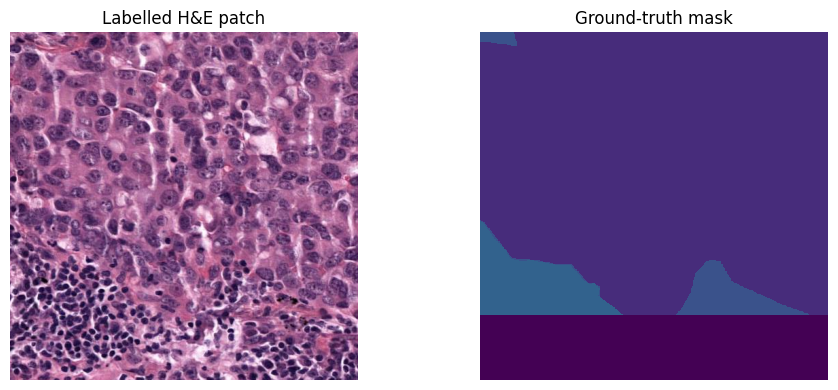

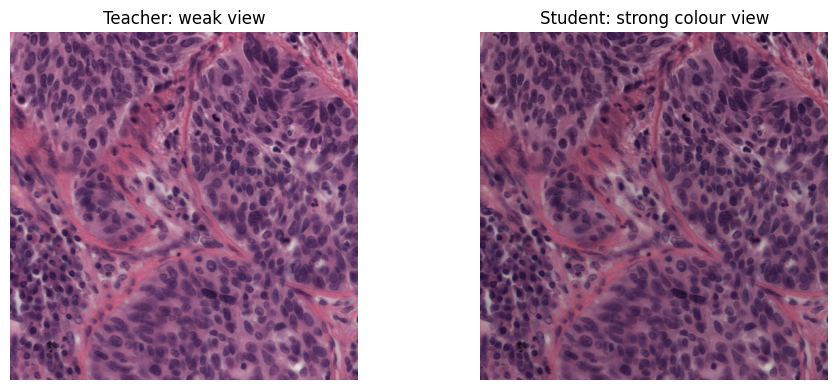

In [9]:
lx, ly = next(iter(labeled_loader))
uw, us = next(iter(unlabeled_loader))
print("Labelled image batch:", tuple(lx.shape), "mask:", tuple(ly.shape))
print("Unlabelled weak/strong:", tuple(uw.shape), tuple(us.shape))
print("Label IDs in labelled batch:", torch.unique(ly).tolist())

# Display first labelled patch (reverse ImageNet normalization).
display_img = lx[0].numpy().transpose(1,2,0)
if USE_IMAGENET_NORMALIZATION:
    display_img = display_img * IMAGENET_STD + IMAGENET_MEAN
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(np.clip(display_img,0,1)); plt.title("Labelled H&E patch"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(ly[0].numpy(), vmin=0, vmax=16, interpolation="nearest"); plt.title("Ground-truth mask"); plt.axis("off")
plt.tight_layout(); plt.show()

weak_img = uw[0].numpy().transpose(1,2,0) * IMAGENET_STD + IMAGENET_MEAN
strong_img = us[0].numpy().transpose(1,2,0) * IMAGENET_STD + IMAGENET_MEAN
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(np.clip(weak_img,0,1)); plt.title("Teacher: weak view"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(np.clip(strong_img,0,1)); plt.title("Student: strong colour view"); plt.axis("off")
plt.tight_layout(); plt.show()

## 10. Build student and teacher networks

Both networks use the same U-Net/ResNet34 architecture. The student encoder starts from ImageNet-pretrained weights. The teacher starts as an exact copy of the student and is then updated using an exponential moving average (EMA); it is never optimized by backpropagation.

In [10]:
def build_model(pretrained_encoder=True):
    return smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet" if pretrained_encoder else None,
        in_channels=3,
        classes=NUM_CLASSES,
        activation=None,
    )

student = build_model(pretrained_encoder=True).to(device)
teacher = build_model(pretrained_encoder=False).to(device)
teacher.load_state_dict(student.state_dict())
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

optimizer = torch.optim.AdamW(student.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
scaler = torch.cuda.amp.GradScaler(enabled=True)

print("Student parameters:", sum(p.numel() for p in student.parameters() if p.requires_grad))
print("Teacher parameters:", sum(p.numel() for p in teacher.parameters()))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Student parameters: 24438689
Teacher parameters: 24438689


/tmp/ipykernel_1355/29820252.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)


## 11. Mean Teacher losses and EMA update

- **Supervised loss:** cross-entropy between student predictions and labelled masks, ignoring pixel ID 0.
- **Consistency loss:** mean-squared difference between teacher and student class-probability maps on unlabelled images. Only teacher pixels with confidence at least `CONFIDENCE_THRESHOLD` and predicted class other than ID 0 are used.
- **Ramp-up:** consistency weight increases gradually over the first few epochs.
- **EMA:** teacher weights are a moving average of student weights. BatchNorm buffers are copied from the student so the teacher uses current running statistics.

In [11]:
def consistency_weight(epoch):
    progress = min(1.0, float(epoch) / max(1, CONSISTENCY_RAMPUP_EPOCHS))
    ramp = math.exp(-5.0 * (1.0 - progress) ** 2)
    return MAX_CONSISTENCY_WEIGHT * ramp

@torch.no_grad()
def update_teacher(student_model, teacher_model, global_step):
    # Bias-corrected early EMA: starts by copying the first student update,
    # then approaches the configured EMA_DECAY.
    alpha = min(EMA_DECAY, 1.0 - 1.0 / float(global_step + 1))
    for t_param, s_param in zip(teacher_model.parameters(), student_model.parameters()):
        t_param.data.mul_(alpha).add_(s_param.data, alpha=1.0-alpha)
    # Keep BatchNorm running statistics and counters in sync with the student.
    for t_buffer, s_buffer in zip(teacher_model.buffers(), student_model.buffers()):
        t_buffer.copy_(s_buffer)
    return alpha

print("Mean Teacher loss/update helpers ready.")

Mean Teacher loss/update helpers ready.


## 12. Validation function (teacher model)

Validation uses full validation ROIs tiled into 512×512 patches. The confusion matrix excludes ground-truth pixels with ID 0. Mean foreground Dice/IoU are calculated over tissue IDs 2–16, matching the supervised notebook.

In [12]:
@torch.inference_mode()
def evaluate_model(model, records, patch_size=512):
    model.eval()
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for row in tqdm(records, desc="Validation ROIs", leave=False):
        image, mask, _ = cached_pair(row["resolved_image"], row["resolved_mask"])
        h, w = mask.shape
        pad_h = (patch_size - h % patch_size) % patch_size
        pad_w = (patch_size - w % patch_size) % patch_size
        if pad_h or pad_w:
            mode = "reflect" if h > 1 and w > 1 else "edge"
            image_eval = np.pad(image, ((0,pad_h),(0,pad_w),(0,0)), mode=mode)
            mask_eval = np.pad(mask, ((0,pad_h),(0,pad_w)), mode="constant", constant_values=IGNORE_INDEX)
        else:
            image_eval, mask_eval = image, mask
        H, W = mask_eval.shape
        for top in range(0, H, patch_size):
            for left in range(0, W, patch_size):
                img_patch = image_eval[top:top+patch_size, left:left+patch_size]
                gt_patch = mask_eval[top:top+patch_size, left:left+patch_size]
                x = image_to_tensor(img_patch).unsqueeze(0).to(device, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=True):
                    logits = model(x)
                pred = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
                valid = gt_patch > IGNORE_INDEX
                if valid.any():
                    encoded = gt_patch[valid].astype(np.int64) * NUM_CLASSES + pred[valid].astype(np.int64)
                    cm += np.bincount(encoded, minlength=NUM_CLASSES*NUM_CLASSES).reshape(NUM_CLASSES, NUM_CLASSES)

    per_class = {}
    dices_fg, ious_fg, dices_all = [], [], []
    for class_id in range(1, NUM_CLASSES):
        tp = cm[class_id, class_id]
        fp = cm[:, class_id].sum() - tp
        fn = cm[class_id, :].sum() - tp
        dden, iden = 2*tp + fp + fn, tp + fp + fn
        dice = float(2*tp/dden) if dden else float("nan")
        iou = float(tp/iden) if iden else float("nan")
        per_class[class_id] = {"class": id_to_label[class_id], "dice": dice, "iou": iou,
                               "support": int(cm[class_id,:].sum())}
        if np.isfinite(dice):
            dices_all.append(dice)
            if class_id >= 2: dices_fg.append(dice)
        if class_id >= 2 and np.isfinite(iou): ious_fg.append(iou)
    metrics = {
        "mean_dice_all_annotated": float(np.mean(dices_all)) if dices_all else 0.0,
        "mean_dice_foreground": float(np.mean(dices_fg)) if dices_fg else 0.0,
        "mean_iou_foreground": float(np.mean(ious_fg)) if ious_fg else 0.0,
    }
    return metrics, per_class, cm

print("Validation function ready.")

Validation function ready.


## 13. Train Mean Teacher and save checkpoints to Drive

The teacher is the primary model evaluated and saved as `best_teacher.pth`. `last_checkpoint.pth` contains both student and teacher weights plus optimizer/scaler state so training can resume after a Colab disconnect.

In [13]:
last_checkpoint_path = OUTPUT_DIR / "last_checkpoint.pth"
best_teacher_path = OUTPUT_DIR / "best_teacher.pth"
history_path = OUTPUT_DIR / "mean_teacher_history.csv"

start_epoch = 1
global_step = 0
best_val_dice = -1.0
history = []

if RESUME_TRAINING:
    if not last_checkpoint_path.is_file():
        raise FileNotFoundError(f"Cannot resume: {last_checkpoint_path} does not exist.")
    checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)
    if checkpoint.get("labeled_patient_ids") != labeled_patient_ids:
        raise ValueError("Labelled patient split differs from the saved checkpoint. Restore the original config/split before resuming.")
    if checkpoint.get("validation_patient_ids") != validation_patient_ids:
        raise ValueError("Validation patient split differs from the saved checkpoint. Restore the original config/split before resuming.")
    student.load_state_dict(checkpoint["student_state_dict"])
    teacher.load_state_dict(checkpoint["teacher_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    start_epoch = int(checkpoint["epoch"]) + 1
    global_step = int(checkpoint.get("global_step", 0))
    best_val_dice = float(checkpoint.get("best_val_dice", -1.0))
    history = checkpoint.get("history", [])
    print(f"Resuming from epoch {start_epoch}; previous best teacher Dice={best_val_dice:.4f}")

steps_per_epoch = len(unlabeled_loader)
if MAX_STEPS_PER_EPOCH is not None:
    steps_per_epoch = min(steps_per_epoch, int(MAX_STEPS_PER_EPOCH))
if steps_per_epoch < 1:
    raise RuntimeError("No unlabelled batches. Check your training split and labelled fraction.")

for epoch in range(start_epoch, EPOCHS + 1):
    student.train()
    teacher.eval()
    labeled_iter = iter(labeled_loader)
    unlabeled_iter = iter(unlabeled_loader)

    sum_sup = sum_cons = sum_total = sum_pseudo_fraction = 0.0
    steps_done = 0
    lambda_u = consistency_weight(epoch)
    progress = tqdm(range(steps_per_epoch), desc=f"Mean Teacher epoch {epoch}/{EPOCHS}")

    for _ in progress:
        try:
            x_l, y_l = next(labeled_iter)
        except StopIteration:
            labeled_iter = iter(labeled_loader)
            x_l, y_l = next(labeled_iter)
        try:
            x_u_weak, x_u_strong = next(unlabeled_iter)
        except StopIteration:
            unlabeled_iter = iter(unlabeled_loader)
            x_u_weak, x_u_strong = next(unlabeled_iter)

        x_l = x_l.to(device, non_blocking=True)
        y_l = y_l.to(device, non_blocking=True)
        x_u_weak = x_u_weak.to(device, non_blocking=True)
        x_u_strong = x_u_strong.to(device, non_blocking=True)

        if not torch.any(y_l != IGNORE_INDEX):
            continue

        optimizer.zero_grad(set_to_none=True)
        # One student forward pass for the labelled and strong unlabelled batches.
        student_input = torch.cat([x_l, x_u_strong], dim=0)
        with torch.cuda.amp.autocast(enabled=True):
            student_logits_all = student(student_input)
            logits_l = student_logits_all[:x_l.shape[0]]
            logits_u_student = student_logits_all[x_l.shape[0]:]
            loss_sup = criterion(logits_l, y_l)

        # Teacher target is generated without gradients from the weak view.
        with torch.no_grad():
            with torch.cuda.amp.autocast(enabled=True):
                logits_u_teacher = teacher(x_u_weak)
            teacher_probs = torch.softmax(logits_u_teacher.float(), dim=1)
            teacher_conf, teacher_pred = teacher_probs.max(dim=1)
            valid_pseudo = (teacher_conf >= CONFIDENCE_THRESHOLD) & (teacher_pred != IGNORE_INDEX)

        student_probs = torch.softmax(logits_u_student.float(), dim=1)
        per_pixel_consistency = (student_probs - teacher_probs.detach()).pow(2).mean(dim=1)
        if valid_pseudo.any():
            loss_cons = per_pixel_consistency[valid_pseudo].mean()
        else:
            loss_cons = per_pixel_consistency.sum() * 0.0

        loss_total = loss_sup + lambda_u * loss_cons
        if not torch.isfinite(loss_total):
            raise RuntimeError("Non-finite Mean Teacher loss. Check data and mask IDs.")

        scaler.scale(loss_total).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(student.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        global_step += 1
        ema_alpha = update_teacher(student, teacher, global_step)

        sum_sup += float(loss_sup.detach().item())
        sum_cons += float(loss_cons.detach().item())
        sum_total += float(loss_total.detach().item())
        sum_pseudo_fraction += float(valid_pseudo.float().mean().item())
        steps_done += 1
        progress.set_postfix(sup=f"{loss_sup.item():.3f}", cons=f"{loss_cons.item():.3f}",
                             pseudo=f"{valid_pseudo.float().mean().item():.2f}", ema=f"{ema_alpha:.3f}")

    if steps_done == 0:
        raise RuntimeError("No training steps completed. Check labelled masks and dataset split.")

    avg_sup = sum_sup / steps_done
    avg_cons = sum_cons / steps_done
    avg_total = sum_total / steps_done
    avg_pseudo = sum_pseudo_fraction / steps_done

    val_metrics, val_per_class, val_cm = evaluate_model(teacher, val_records, patch_size=PATCH_SIZE)
    val_score = val_metrics["mean_dice_foreground"]
    scheduler.step(val_score)

    row = {
        "epoch": epoch,
        "supervised_loss": avg_sup,
        "consistency_loss": avg_cons,
        "total_loss": avg_total,
        "consistency_weight": lambda_u,
        "pseudo_label_coverage": avg_pseudo,
        "val_mean_dice_foreground": val_metrics["mean_dice_foreground"],
        "val_mean_dice_all_annotated": val_metrics["mean_dice_all_annotated"],
        "val_mean_iou_foreground": val_metrics["mean_iou_foreground"],
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(row)
    pd.DataFrame(history).to_csv(history_path, index=False)

    checkpoint_to_save = {
        "epoch": epoch,
        "student_state_dict": student.state_dict(),
        "teacher_state_dict": teacher.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "global_step": global_step,
        "best_val_dice": max(best_val_dice, val_score),
        "val_metrics": val_metrics,
        "history": history,
        "labeled_patient_ids": labeled_patient_ids,
        "unlabeled_patient_ids": unlabeled_patient_ids,
        "validation_patient_ids": validation_patient_ids,
        "labeled_fraction": LABELED_FRACTION,
        "confidence_threshold": CONFIDENCE_THRESHOLD,
        "ema_decay": EMA_DECAY,
        "patch_size": PATCH_SIZE,
        "num_classes": NUM_CLASSES,
        "ignore_index": IGNORE_INDEX,
        "normalization": "ImageNet mean/std",
    }

    # Save locally first, then copy to persistent Drive storage.
    local_last = Path("/content/mean_teacher_last_checkpoint.pth")
    torch.save(checkpoint_to_save, local_last)
    shutil.copy2(local_last, last_checkpoint_path)

    if val_score > best_val_dice:
        best_val_dice = val_score
        best_payload = {
            "epoch": epoch,
            "model_state_dict": teacher.state_dict(),
            "val_metrics": val_metrics,
            "per_class_dice": val_per_class,
            "labeled_patient_ids": labeled_patient_ids,
            "validation_patient_ids": validation_patient_ids,
            "labeled_fraction": LABELED_FRACTION,
            "confidence_threshold": CONFIDENCE_THRESHOLD,
            "ema_decay": EMA_DECAY,
            "patch_size": PATCH_SIZE,
            "num_classes": NUM_CLASSES,
            "ignore_index": IGNORE_INDEX,
        }
        local_best = Path("/content/mean_teacher_best_teacher.pth")
        torch.save(best_payload, local_best)
        shutil.copy2(local_best, best_teacher_path)
        print(f"Saved new best teacher: foreground mean Dice={best_val_dice:.4f}")

    print(
        f"Epoch {epoch}: sup={avg_sup:.4f} | consistency={avg_cons:.4f} | "
        f"pseudo coverage={avg_pseudo:.1%} | teacher val Dice={val_metrics['mean_dice_foreground']:.4f} | "
        f"val IoU={val_metrics['mean_iou_foreground']:.4f}"
    )

print("Training loop finished.")
print("Best teacher:", best_teacher_path)
print("Last checkpoint:", last_checkpoint_path)
print("History:", history_path)

Mean Teacher epoch 1/10:   0%|          | 0/93 [00:00<?, ?it/s]

/tmp/ipykernel_1355/1159063809.py:69: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):
/tmp/ipykernel_1355/1159063809.py:77: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


Validation ROIs:   0%|          | 0/51 [00:00<?, ?it/s]

/tmp/ipykernel_1355/3246183621.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


Saved new best teacher: foreground mean Dice=0.0833
Epoch 1: sup=2.3588 | consistency=0.0041 | pseudo coverage=0.0% | teacher val Dice=0.0833 | val IoU=0.0489


Mean Teacher epoch 2/10:   0%|          | 0/93 [00:00<?, ?it/s]

... (22 outputs left out)

Saved new best teacher: foreground mean Dice=0.1268
Epoch 9: sup=1.1787 | consistency=0.0119 | pseudo coverage=31.8% | teacher val Dice=0.1268 | val IoU=0.0838


Mean Teacher epoch 10/10:   0%|          | 0/93 [00:00<?, ?it/s]

Validation ROIs:   0%|          | 0/51 [00:00<?, ?it/s]

Saved new best teacher: foreground mean Dice=0.1692
Epoch 10: sup=1.1891 | consistency=0.0165 | pseudo coverage=35.5% | teacher val Dice=0.1692 | val IoU=0.1217
Training loop finished.
Best teacher: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_mean_teacher_20pct/best_teacher.pth
Last checkpoint: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_mean_teacher_20pct/last_checkpoint.pth
History: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_mean_teacher_20pct/mean_teacher_history.csv


## 14. Plot training history and inspect validation metrics

,epoch,supervised_loss,consistency_loss,total_loss,consistency_weight,pseudo_label_coverage,val_mean_dice_foreground,val_mean_dice_all_annotated,val_mean_iou_foreground,learning_rate
5,6,1.307261,0.007172,1.310847,0.5,0.155166,0.113385,0.151956,0.077396,0.0001
6,7,1.165936,0.009409,1.170640,0.5,0.250993,0.125479,0.163352,0.088946,0.0001
7,8,1.211986,0.012314,1.218143,0.5,0.305917,0.110166,0.143048,0.070319,0.0001
8,9,1.178734,0.011909,1.184688,0.5,0.317893,0.126768,0.164465,0.083787,0.0001
9,10,1.189052,0.016489,1.197296,0.5,0.354690,0.169181,0.206245,0.121701,0.0001


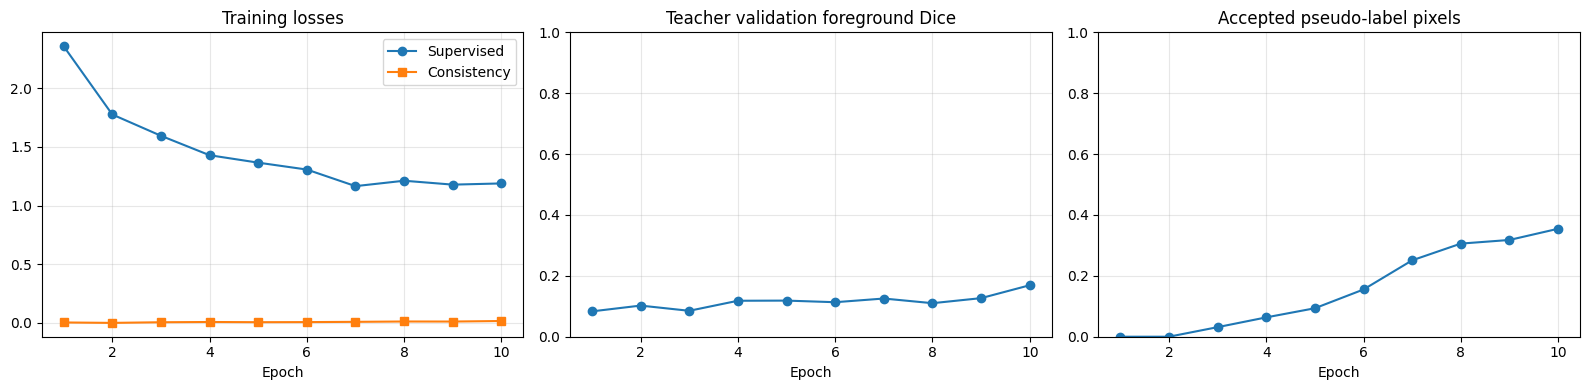

In [14]:
if history_path.exists():
    history_df = pd.read_csv(history_path)
else:
    history_df = pd.DataFrame(history)
display(history_df.tail())

if not history_df.empty:
    fig, axes = plt.subplots(1, 3, figsize=(16,4))
    axes[0].plot(history_df["epoch"], history_df["supervised_loss"], marker="o", label="Supervised")
    axes[0].plot(history_df["epoch"], history_df["consistency_loss"], marker="s", label="Consistency")
    axes[0].set_title("Training losses"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True, alpha=.3)
    axes[1].plot(history_df["epoch"], history_df["val_mean_dice_foreground"], marker="o")
    axes[1].set_title("Teacher validation foreground Dice"); axes[1].set_xlabel("Epoch"); axes[1].set_ylim(0,1); axes[1].grid(True, alpha=.3)
    axes[2].plot(history_df["epoch"], history_df["pseudo_label_coverage"], marker="o")
    axes[2].set_title("Accepted pseudo-label pixels"); axes[2].set_xlabel("Epoch"); axes[2].set_ylim(0,1); axes[2].grid(True, alpha=.3)
    plt.tight_layout(); plt.show()

## 15. Load the best teacher and export class-wise validation results

In [15]:
if not best_teacher_path.is_file():
    raise FileNotFoundError("best_teacher.pth not found. Run the training cell first.")

best_teacher_ckpt = torch.load(best_teacher_path, map_location=device, weights_only=False)
teacher.load_state_dict(best_teacher_ckpt["model_state_dict"])
teacher.eval()
final_metrics, final_per_class, final_cm = evaluate_model(teacher, val_records, PATCH_SIZE)

class_rows = []
for class_id in range(1, NUM_CLASSES):
    item = final_per_class[class_id]
    class_rows.append({
        "class_id": class_id,
        "class_name": item["class"],
        "Dice": item["dice"],
        "IoU": item["iou"],
        "ground_truth_pixels": item["support"],
    })
class_metrics_df = pd.DataFrame(class_rows)
display(class_metrics_df)
print("Best teacher validation summary:", final_metrics)
class_metrics_df.to_csv(OUTPUT_DIR / "teacher_validation_class_metrics.csv", index=False)
np.save(OUTPUT_DIR / "teacher_validation_confusion_matrix.npy", final_cm)


Validation ROIs:   0%|          | 0/51 [00:00<?, ?it/s]

/tmp/ipykernel_1355/3246183621.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


,class_id,class_name,Dice,IoU,ground_truth_pixels
0,1,Background,7.251398e-01,5.687995e-01,16078512
1,2,Tumor epithelium,6.844654e-01,5.202944e-01,15804792
2,3,Reactive epithelium,5.135915e-03,2.574569e-03,1959397
3,4,Stroma,7.400636e-01,5.873817e-01,37793812
4,5,Inflammation,5.363575e-01,3.664539e-01,3573854
5,6,Alveolar tissue,4.650927e-07,2.325464e-07,4300206
6,7,Fatty tissue,0.000000e+00,0.000000e+00,550951
7,8,Necrotic tissue,2.612135e-03,1.307776e-03,3782464
8,9,Erythrocytes,3.312946e-03,1.659221e-03,2380107
9,10,Bronchial epithelium,1.216480e-01,6.476314e-02,272399


Best teacher validation summary: {'mean_dice_all_annotated': 0.20624489882378513, 'mean_dice_foreground': 0.16918097534459148, 'mean_iou_foreground': 0.12170072610584058}


## 16. Visualize a validation ROI: image, ground truth, teacher prediction

/tmp/ipykernel_1355/2303096829.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


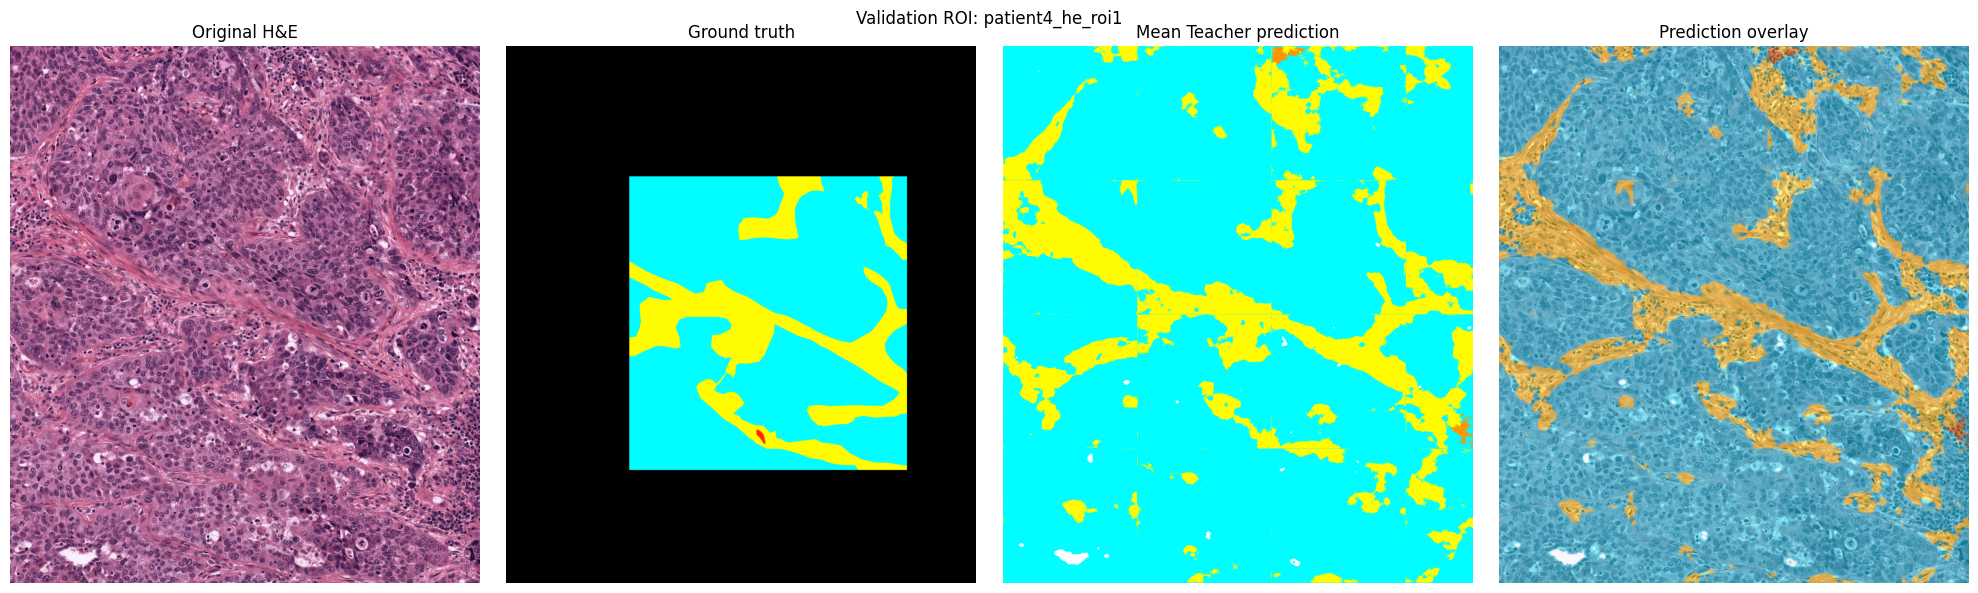

In [16]:
PALETTE = np.array([
    [0,0,0], [255,255,255], [0,253,255], [0,249,0], [255,251,0],
    [255,147,0], [255,47,146], [148,55,255], [1,25,147], [255,38,0],
    [0,143,0], [146,144,0], [169,169,169], [83,27,147], [255,126,121],
    [215,131,255], [148,23,81]
], dtype=np.uint8)

@torch.inference_mode()
def predict_roi(model, image, patch_size=512):
    model.eval()
    h, w = image.shape[:2]
    pred_full = np.zeros((h,w), dtype=np.uint8)
    for top in range(0,h,patch_size):
        for left in range(0,w,patch_size):
            patch = image[top:min(top+patch_size,h), left:min(left+patch_size,w)]
            ph,pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                mode = "reflect" if ph > 1 and pw > 1 else "edge"
                patch = np.pad(patch, ((0,patch_size-ph),(0,patch_size-pw),(0,0)), mode=mode)
            x = image_to_tensor(patch).unsqueeze(0).to(device)
            with torch.cuda.amp.autocast(enabled=True):
                logits = model(x)
            pred = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
            pred_full[top:top+ph, left:left+pw] = pred[:ph,:pw]
    return pred_full

vis_row = val_records[0]
vis_image, vis_mask = read_image_mask(vis_row["resolved_image"], vis_row["resolved_mask"])
vis_pred = predict_roi(teacher, vis_image, PATCH_SIZE)
gt_rgb, pred_rgb = PALETTE[vis_mask], PALETTE[vis_pred]
overlay = (0.55*vis_image.astype(np.float32) + 0.45*pred_rgb.astype(np.float32)).clip(0,255).astype(np.uint8)

fig, axes = plt.subplots(1,4,figsize=(20,6))
axes[0].imshow(vis_image); axes[0].set_title("Original H&E")
axes[1].imshow(gt_rgb); axes[1].set_title("Ground truth")
axes[2].imshow(pred_rgb); axes[2].set_title("Mean Teacher prediction")
axes[3].imshow(overlay); axes[3].set_title("Prediction overlay")
for ax in axes: ax.axis("off")
plt.suptitle(f"Validation ROI: {vis_row['name']}")
plt.tight_layout(); plt.show()

## 17. Outputs and next research steps

The output folder in Drive is:

`MyDrive/IGNITE/training_outputs/ignite_he_mean_teacher_20pct/`

Expected files:
- `best_teacher.pth` — best EMA teacher model weights and metadata.
- `last_checkpoint.pth` — student, teacher, optimizer, scaler, scheduler, and resume state.
- `mean_teacher_history.csv` — losses, pseudo-label coverage, and validation metrics.
- `teacher_validation_class_metrics.csv` — per-class Dice/IoU.
- `teacher_validation_confusion_matrix.npy` — validation confusion matrix.

### If Colab disconnects
1. Reconnect and rerun cells 1–13 to remount Drive, stage files, rebuild the same split, and recreate models/loaders.
2. In the Configuration cell set `RESUME_TRAINING = True`.
3. Set `EPOCHS` to the final target epoch (greater than the checkpoint epoch).
4. Rerun the training cell.

### How to interpret the run
- `supervised_loss` should generally trend down.
- `consistency_loss` is not expected to decrease monotonically in every epoch.
- `pseudo_label_coverage` tells you what fraction of unlabelled pixels passed the teacher confidence threshold and were not predicted as ignored class 0. Very low coverage can mean the threshold is too strict or the teacher is not confident yet.
- Watch validation Dice and class-wise metrics, not just the training losses.

### For a defensible research comparison
Train a separate supervised control using **the same `labeled_patient_ids`** (same 20% label budget), same training crops, same validation set, and same evaluation code. Compare that control with Mean Teacher. Do not claim that Mean Teacher beats supervised learning merely by comparing it with the earlier model trained on a larger labelled set.

After the initial 20% run, you can repeat with 10%, 25%, and 50% labelled patients. Keep the validation split fixed and record the patient IDs and random seeds for every experiment.